# Generative Adversarial Network on a Ring of Gaussians

This notebook implements a **Generative Adversarial Network (GAN)** from first principles in PyTorch on a two-dimensional ring of Gaussians.

### Learning goals
1. Explain the minmax game between the generator and the discriminator.
2. Distinguish the original minmax and non-saturating generator losses.
3. Implement alternating discriminator and generator updates correctly.
4. Visualize the discriminator's evolving decision landscape.
5. Diagnose mode collapse and understand why GAN losses are unusual metrics.

In two dimensions, adversarial training and its failure modes can be inspected directly. The same components later become convolutional networks for images.

## Before you begin

**Prerequisites.** You should be comfortable with binary classification and logits, gradient-based neural-network training, expectations over samples, and PyTorch optimization. Familiarity with maximum likelihood helps with comparison, but GANs do not expose a tractable likelihood here.

> **Notation and orientation**
> - $z\sim p(z)$ is latent noise. $G_\theta(z)$ is a generated point. $D_\phi(x)$ outputs a real/fake logit.
> - The discriminator improves classification of real and fake samples. The generator receives gradients through the discriminator and uses the non-saturating objective.
> - Training alternates the two players. **Generation** is one parallel pass $z\rightarrow G_\theta(z)$. $D_\phi$ is not needed afterward.

## 1. Setup

Only NumPy, Matplotlib, and PyTorch are required. Training uses a GPU automatically when available.

**Runtime:** This toy model trains directly in the notebook. Expect roughly tens of seconds on a recent GPU and up to a few minutes on CPU. The exact time depends on your hardware.


In [1]:
import copy
import random
import time
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PLOT_THEME = "light"  # Change to "dark" for the dark plot palette.
if PLOT_THEME not in {"light", "dark"}:
    raise ValueError("PLOT_THEME must be 'light' or 'dark'.")

# Start from Matplotlib defaults so light mode keeps the standard coloring.
plt.style.use("default")
if PLOT_THEME == "dark":
    plt.style.use("dark_background")
    plt.rcParams.update(
        {
            "figure.facecolor": "#0a0f18",
            "figure.edgecolor": "#0a0f18",
            "axes.facecolor": "#111926",
            "axes.edgecolor": "#e8eff9",
            "axes.labelcolor": "#e8eff9",
            "axes.titlecolor": "#e8eff9",
            "text.color": "#e8eff9",
            "xtick.color": "#e8eff9",
            "ytick.color": "#e8eff9",
            "grid.color": "#2b3340",
            "savefig.facecolor": "#0a0f18",
            "savefig.edgecolor": "#0a0f18",
        }
    )

PLOT_REFERENCE_COLOR = "black" if PLOT_THEME == "light" else "#6cd2e8"
PLOT_GENERATED_COLOR = "tab:orange" if PLOT_THEME == "light" else "#f09a4b"
PLOT_GUIDE_COLOR = "black" if PLOT_THEME == "light" else "#e8eff9"

plt.rcParams.update({"figure.figsize": (6, 5), "axes.grid": True, "grid.alpha": 0.25, "font.size": 11})
print(f"PyTorch {torch.__version__} | device: {DEVICE}")

PyTorch 2.12.0+cu130 | device: cuda


## 2. Data: a ring of Gaussians

We use an equally weighted mixture of $K$ isotropic Gaussian components:

$$\mu_k=r[\cos(2\pi k/K),\sin(2\pi k/K)]^\top,\qquad
x\mid k\sim\mathcal N(\mu_k,\sigma_{data}^2I).$$

Labels are retained only for visualization and evaluation. Neither adversary sees them.

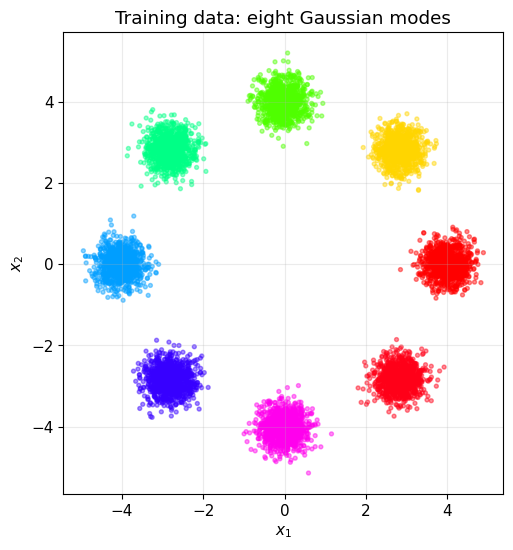

Train shape: (8000, 2)


In [2]:
def sample_ring(n_samples, n_modes=8, radius=4.0, std=0.30, seed=0):
    """Return observations and visualization-only component labels."""
    g = torch.Generator().manual_seed(seed)
    labels = torch.randint(n_modes, (n_samples,), generator=g)
    angles = 2 * torch.pi * labels.float() / n_modes
    centers = radius * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
    return centers + std * torch.randn(n_samples, 2, generator=g), labels


N_MODES, RADIUS, DATA_STD = 8, 4.0, 0.30
x_train, y_train = sample_ring(8_000, N_MODES, RADIUS, DATA_STD, SEED)
x_test, y_test = sample_ring(2_000, N_MODES, RADIUS, DATA_STD, SEED + 1)
train_loader = DataLoader(
    TensorDataset(x_train),
    batch_size=256,
    shuffle=True,
    drop_last=True,
    generator=torch.Generator().manual_seed(SEED),
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x_train[:, 0], x_train[:, 1], c=y_train, cmap="hsv", s=8, alpha=0.45)
ax.set(title="Training data: eight Gaussian modes", xlabel="$x_1$", ylabel="$x_2$")
ax.set_aspect("equal")
plt.show()
print("Train shape:", tuple(x_train.shape))

## 3. The adversarial game

A GAN contains two networks:

- the **generator** $G_\theta(z)$ maps noise $z\sim p(z)$ to synthetic data;
- the **discriminator** $D_\phi(x)\in(0,1)$ predicts whether a point is real.

The original minmax objective is

$$\min_\theta\max_\phi\;
\mathbb E_{x\sim p_{data}}[\log D_\phi(x)]
+\mathbb E_{z\sim p(z)}[\log(1-D_\phi(G_\theta(z)))].$$

For a fixed generator, the optimal discriminator is

$$D^*(x)=\frac{p_{data}(x)}{p_{data}(x)+p_G(x)}.$$

Substituting $D^*$ shows that idealized GAN training minimizes the Jensen–Shannon divergence. At equilibrium, $p_G=p_{data}$ and $D(x)=1/2$ everywhere.

## 4. Practical generator loss

The minmax generator loss $\mathbb E[\log(1-D(G(z)))]$ can have weak gradients when the discriminator confidently rejects early samples. In practice, the common **non-saturating loss** is

$$\mathcal L_G=-\mathbb E_z[\log D(G(z))].$$

It has the same desired equilibrium but gives stronger early gradients. We implement losses from discriminator **logits** with binary cross entropy for numerical stability.

We also use two mild stabilizers:

- **one-sided label smoothing:** the real target is $0.9$ rather than $1$;
- **instance noise:** small Gaussian noise is added to discriminator inputs and annealed to zero, initially smoothing the disjoint real and generated distributions.

In [3]:
LATENT_DIM = 2


class Generator(nn.Module):
    def __init__(self, latent_dim=2, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(latent_dim, hidden),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden, 2),
        )

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(2, hidden),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden, hidden),
            nn.LeakyReLU(0.2),
            nn.Linear(hidden, 1),
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)  # logits, not probabilities


G = Generator(LATENT_DIM, hidden=128).to(DEVICE)
D = Discriminator(hidden=256).to(DEVICE)  #128
print(G)
print(D)
print(f"Generator parameters: {sum(p.numel() for p in G.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in D.parameters()):,}")

Generator(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=128, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=128, out_features=2, bias=True)
  )
)
Discriminator(
  (net): Sequential(
    (0): Linear(in_features=2, out_features=256, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Linear(in_features=256, out_features=256, bias=True)
    (3): LeakyReLU(negative_slope=0.2)
    (4): Linear(in_features=256, out_features=1, bias=True)
  )
)
Generator parameters: 17,154
Discriminator parameters: 66,817


## 5. Alternating optimization

Each iteration performs two distinct optimization steps:

1. **Discriminator step:** classify real samples as real and detached generated samples as fake.
2. **Generator step:** generate a fresh batch and update $G$ so $D$ classifies it as real.

Detaching generated samples during the discriminator update is important, since that step should not alter the generator. Conversely, discriminator parameters are temporarily frozen during the generator update to avoid computing unnecessary discriminator gradients.

In [4]:
def discriminator_loss(real_logits, fake_logits, real_target=0.9):
    real_loss = F.binary_cross_entropy_with_logits(
        real_logits, torch.full_like(real_logits, real_target)
    )
    fake_loss = F.binary_cross_entropy_with_logits(
        fake_logits, torch.zeros_like(fake_logits)
    )
    return real_loss + fake_loss


def generator_loss(fake_logits):
    return F.binary_cross_entropy_with_logits(fake_logits, torch.ones_like(fake_logits))


# Shape and gradient sanity checks.
z = torch.randn(16, LATENT_DIM, device=DEVICE)
fake = G(z)
real_logits, fake_logits = D(x_train[:16].to(DEVICE)), D(fake)
d_loss = discriminator_loss(real_logits, fake_logits.detach())
g_loss = generator_loss(fake_logits)
assert fake.shape == (16, 2)
assert real_logits.shape == fake_logits.shape == (16,)
assert torch.isfinite(d_loss + g_loss)
print(
    f"Sanity check passed | initial D loss: {d_loss.item():.3f} | G loss: {g_loss.item():.3f}"
)

Sanity check passed | initial D loss: 1.499 | G loss: 0.695


## 6. Train

GAN training is a dynamic game rather than minimization of one fixed scalar objective. We save generator snapshots to visualize its evolution. Losses often oscillate and are not reliable standalone measures of sample quality.

In [5]:
EPOCHS = 500  # 300
LR_G = 2e-4
LR_D = 5e-4
optimizer_G = torch.optim.Adam(G.parameters(), lr=LR_G, betas=(0.5, 0.999))
optimizer_D = torch.optim.Adam(D.parameters(), lr=LR_D, betas=(0.5, 0.999))
history = {"generator": [], "discriminator": [], "D_real": [], "D_fake": []}
snapshot_epochs = [1, 10, 30, 75, 150, 300]
snapshots = {}
start = time.time()

for epoch in range(1, EPOCHS + 1):
    G.train()
    D.train()
    totals = np.zeros(4)
    # noise_std = 0.15 * max(0.0, 1 - epoch / 100)
    noise_std = 0.1 * max(0.0, 1 - epoch / 100)

    for (real,) in train_loader:
        real = real.to(DEVICE)
        batch_size = len(real)

        # 1) Update discriminator. Generated data are detached from G's graph.
        optimizer_D.zero_grad(set_to_none=True)
        with torch.no_grad():
            fake_for_D = G(torch.randn(batch_size, LATENT_DIM, device=DEVICE))
        noisy_real = real + noise_std * torch.randn_like(real)
        noisy_fake = fake_for_D + noise_std * torch.randn_like(fake_for_D)
        real_logits = D(noisy_real)
        fake_logits = D(noisy_fake)
        d_loss = discriminator_loss(real_logits, fake_logits)
        d_loss.backward()
        optimizer_D.step()

        # 2) Update generator through the frozen discriminator computation.
        for parameter in D.parameters():
            parameter.requires_grad_(False)
        optimizer_G.zero_grad(set_to_none=True)
        fake_for_G = G(torch.randn(batch_size, LATENT_DIM, device=DEVICE))
        fake_logits_for_G = D(fake_for_G)
        g_loss = generator_loss(fake_logits_for_G)
        g_loss.backward()
        optimizer_G.step()
        for parameter in D.parameters():
            parameter.requires_grad_(True)

        totals += (
            np.array(
                [
                    g_loss.item(),
                    d_loss.item(),
                    real_logits.sigmoid().mean().item(),
                    fake_logits.sigmoid().mean().item(),
                ]
            )
            * batch_size
        )

    averages = totals / (len(train_loader) * train_loader.batch_size)
    for key, value in zip(history, averages):
        history[key].append(value)
    if epoch in snapshot_epochs:
        snapshots[epoch] = copy.deepcopy(G.state_dict())
    if epoch == 1 or epoch % 50 == 0:
        print(
            f"epoch {epoch:3d} | D loss {averages[1]:.3f} | G loss {averages[0]:.3f} | "
            f"D(real) {averages[2]:.3f} | D(fake) {averages[3]:.3f}"
        )
print(f"Training time: {time.time() - start:.1f} s")

epoch   1 | D loss 0.806 | G loss 1.308 | D(real) 0.767 | D(fake) 0.317
epoch  50 | D loss 1.164 | G loss 1.317 | D(real) 0.546 | D(fake) 0.356
epoch 100 | D loss 1.232 | G loss 1.154 | D(real) 0.521 | D(fake) 0.376
epoch 150 | D loss 1.266 | G loss 1.083 | D(real) 0.512 | D(fake) 0.388
epoch 200 | D loss 1.281 | G loss 1.027 | D(real) 0.499 | D(fake) 0.401
epoch 250 | D loss 1.301 | G loss 0.987 | D(real) 0.490 | D(fake) 0.409
epoch 300 | D loss 1.302 | G loss 0.954 | D(real) 0.488 | D(fake) 0.411
epoch 350 | D loss 1.317 | G loss 0.946 | D(real) 0.484 | D(fake) 0.415
epoch 400 | D loss 1.316 | G loss 0.935 | D(real) 0.485 | D(fake) 0.416
epoch 450 | D loss 1.322 | G loss 0.913 | D(real) 0.480 | D(fake) 0.420
epoch 500 | D loss 1.326 | G loss 0.903 | D(real) 0.480 | D(fake) 0.422
Training time: 65.6 s


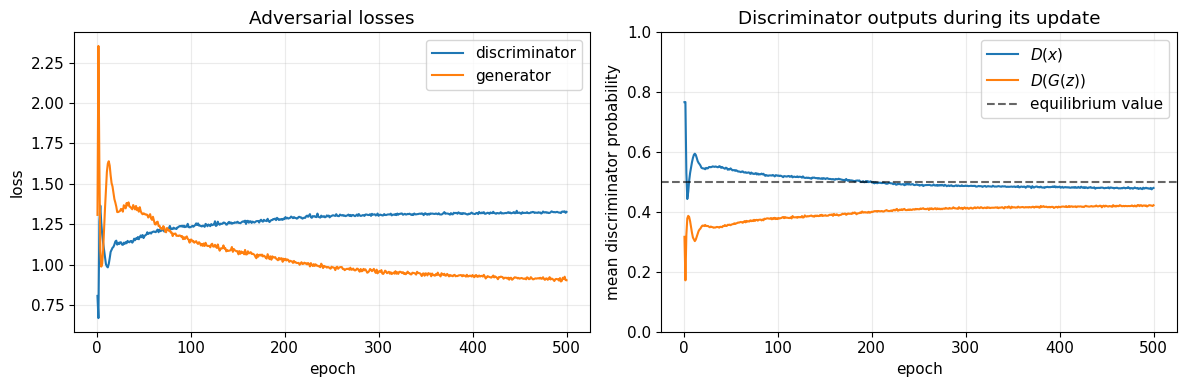

In [6]:
epochs = np.arange(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs, history["discriminator"], label="discriminator")
axes[0].plot(epochs, history["generator"], label="generator")
axes[0].set(xlabel="epoch", ylabel="loss", title="Adversarial losses")
axes[0].legend()
axes[1].plot(epochs, history["D_real"], label="$D(x)$")
axes[1].plot(epochs, history["D_fake"], label="$D(G(z))$")
axes[1].axhline(
    0.5, color=PLOT_GUIDE_COLOR, linestyle="--", alpha=0.6, label="equilibrium value"
)
axes[1].set(
    xlabel="epoch",
    ylabel="mean discriminator probability",
    ylim=(0, 1),
    title="Discriminator outputs during its update",
)
axes[1].legend()
plt.tight_layout()
plt.show()

## 7. How the generator distribution evolves

Each panel uses the same fixed latent points with a saved generator snapshot. Early generators often produce one cloud or curved filament before discovering the modes. A run that permanently covers only a subset exhibits **mode collapse**.

> **Predict before running.** Across saved checkpoints, will the generator discover all modes at once, move between subsets, or steadily fill the ring? **Commit to a predicted trajectory and explain how alternating adversarial gradients could produce it.**

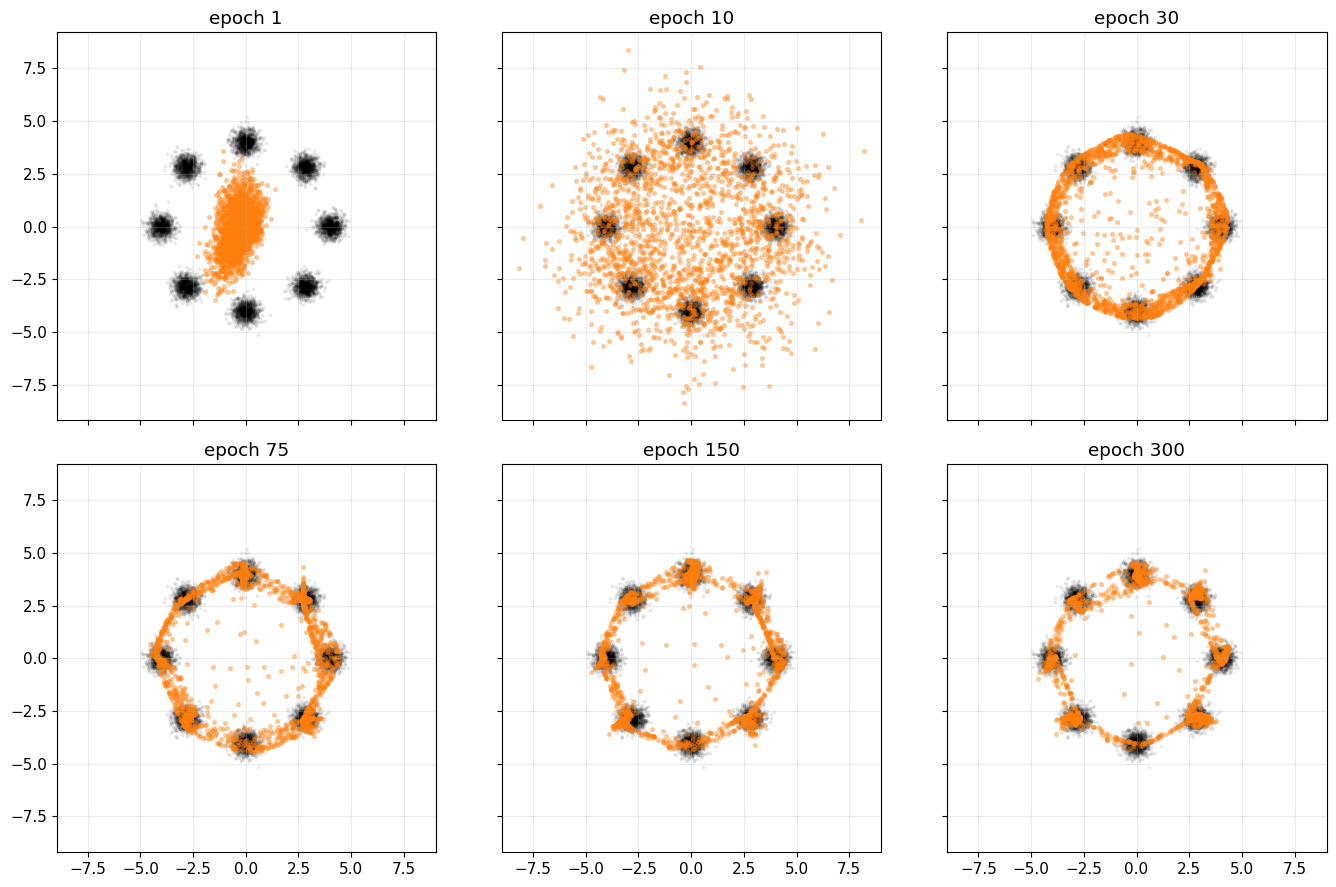

In [7]:
fixed_z = torch.randn(
    2_000, LATENT_DIM, generator=torch.Generator().manual_seed(123)
).to(DEVICE)
current_state = copy.deepcopy(G.state_dict())
fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharex=True, sharey=True)
for ax, epoch in zip(axes.ravel(), snapshot_epochs):
    G.load_state_dict(snapshots[epoch])
    G.eval()
    with torch.no_grad():
        points = G(fixed_z).cpu()
    ax.scatter(x_train[:, 0], x_train[:, 1], s=3, alpha=0.06, color=PLOT_REFERENCE_COLOR)
    ax.scatter(points[:, 0], points[:, 1], s=7, alpha=0.35, color=PLOT_GENERATED_COLOR)
    ax.set_title(f"epoch {epoch}")
    ax.set_aspect("equal")
G.load_state_dict(current_state)
plt.tight_layout()
plt.show()

> **Expected observation / interpretation.** Coverage typically evolves non-monotonically. The generated mass may migrate, split, or temporarily favor a subset of modes. The discriminator supplies a changing relative signal, so adversarial progress does not need to resemble smooth maximum-likelihood improvement.

## 8. Final samples

Generation requires only the generator:

$$z\sim\mathcal N(0,I),\qquad x=G_\theta(z).$$

There is no encoder, explicit likelihood, or sequential coordinate loop. All samples can be generated in parallel.

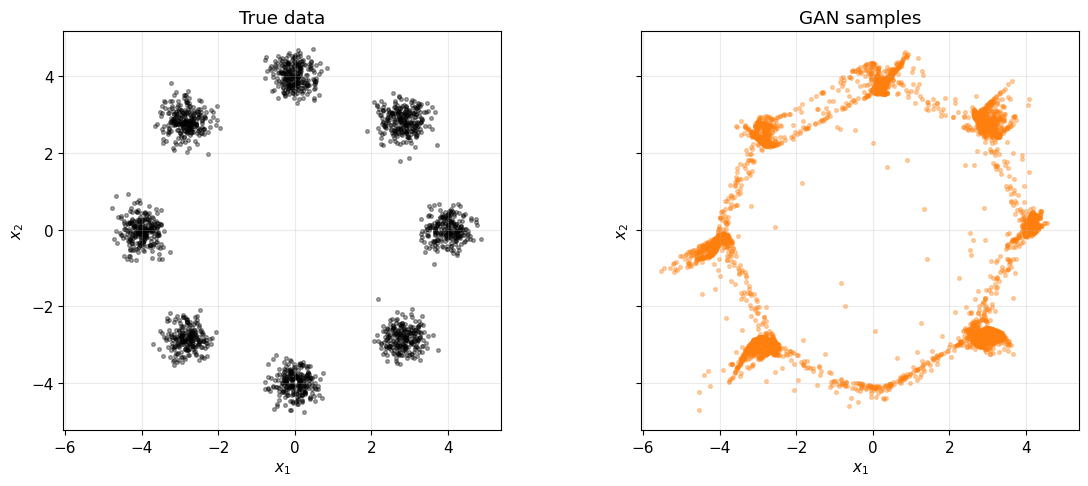

In [8]:
G.eval()
D.eval()
with torch.no_grad():
    generated = G(torch.randn(5_000, LATENT_DIM, device=DEVICE)).cpu()

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
axes[0].scatter(x_test[:, 0], x_test[:, 1], s=7, alpha=0.35, color=PLOT_REFERENCE_COLOR)
axes[0].set_title("True data")
axes[1].scatter(generated[:, 0], generated[:, 1], s=7, alpha=0.35, color=PLOT_GENERATED_COLOR)
axes[1].set_title("GAN samples")
for ax in axes:
    ax.set(xlabel="$x_1$", ylabel="$x_2$")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

## 9. Visualize the discriminator

The discriminator learns a classification surface, not a normalized data density. Its gradients tell generated points how to move to look more real.

At a perfect equilibrium, the discriminator would output $1/2$ everywhere the two distributions overlap. A non-flat final landscape indicates that the adversaries have not reached the ideal equilibrium which is normal in finite training.

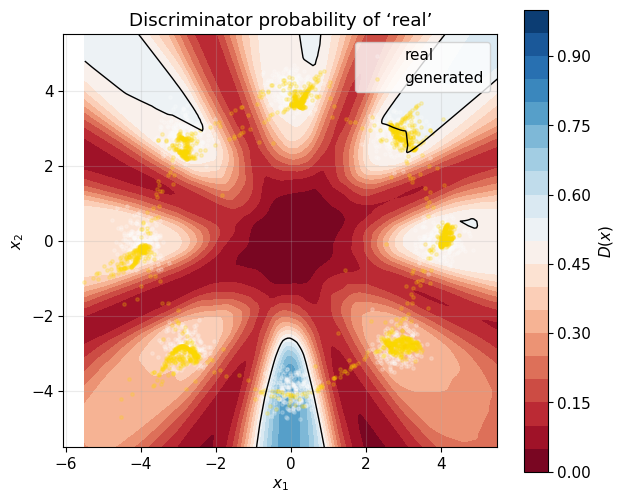

In [9]:
limit, resolution = 5.5, 180
axis = torch.linspace(-limit, limit, resolution)
xx, yy = torch.meshgrid(axis, axis, indexing="xy")
grid = torch.stack([xx.ravel(), yy.ravel()], dim=1)
probability_parts = []
with torch.no_grad():
    for chunk in grid.split(4096):
        probability_parts.append(D(chunk.to(DEVICE)).sigmoid().cpu())
disc_probability = torch.cat(probability_parts).reshape(resolution, resolution)

fig, ax = plt.subplots(figsize=(7, 6))
filled = ax.contourf(
    xx, yy, disc_probability, levels=np.linspace(0, 1, 21), cmap="RdBu", vmin=0, vmax=1
)
ax.contour(xx, yy, disc_probability, levels=[0.5], colors=PLOT_GUIDE_COLOR, linewidths=1)
ax.scatter(x_test[:, 0], x_test[:, 1], s=6, alpha=0.2, color="white", label="real")
ax.scatter(
    generated[:2000, 0],
    generated[:2000, 1],
    s=6,
    alpha=0.2,
    color="gold",
    label="generated",
)
ax.set(title="Discriminator probability of ‘real’", xlabel="$x_1$", ylabel="$x_2$")
ax.set_aspect("equal")
ax.legend()
fig.colorbar(filled, ax=ax, label="$D(x)$")
plt.show()

## 10. The generator as a learned map

The generator continuously warps the connected latent plane into data space. Decoding a regular latent grid shows this geometry. Color indicates the base Gaussian density: central, high-probability latent points should ideally map into high-probability data regions.

As with VAEs and ordinary flows, a continuous map from a connected latent space cannot create truly disconnected support. It can make connecting regions carry very little probability by stretching them.

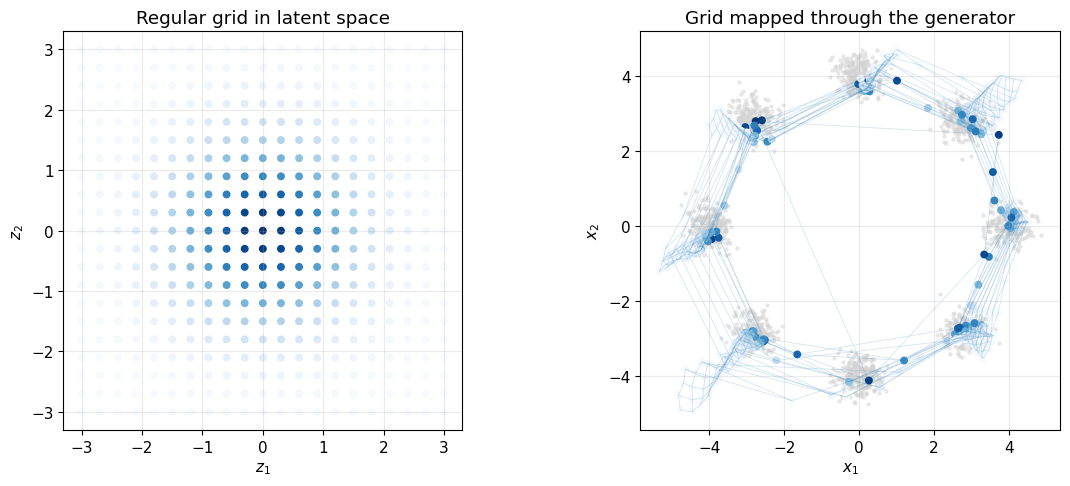

In [10]:
latent_axis = torch.linspace(-3, 3, 21)
z1, z2 = torch.meshgrid(latent_axis, latent_axis, indexing="xy")
z_grid = torch.stack([z1.ravel(), z2.ravel()], dim=1)
latent_density = torch.exp(-0.5 * (z1**2 + z2**2)) / (2 * torch.pi)
with torch.no_grad():
    decoded_grid = G(z_grid.to(DEVICE)).cpu()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(
    z_grid[:, 0], z_grid[:, 1], c=latent_density.ravel(), cmap="Blues", s=22
)
axes[0].set(title="Regular grid in latent space", xlabel="$z_1$", ylabel="$z_2$")
axes[0].set_aspect("equal")
axes[1].scatter(x_test[:, 0], x_test[:, 1], s=5, color="lightgray", alpha=0.4)
axes[1].scatter(
    decoded_grid[:, 0], decoded_grid[:, 1], c=latent_density.ravel(), cmap="Blues", s=22
)
# Draw rows and columns separately to expose the deformation.
for row in decoded_grid.reshape(21, 21, 2):
    axes[1].plot(row[:, 0], row[:, 1], color="tab:blue", alpha=0.18, linewidth=0.6)
for col in decoded_grid.reshape(21, 21, 2).transpose(0, 1):
    axes[1].plot(col[:, 0], col[:, 1], color="tab:blue", alpha=0.18, linewidth=0.6)
axes[1].set(title="Grid mapped through the generator", xlabel="$x_1$", ylabel="$x_2$")
axes[1].set_aspect("equal")
plt.tight_layout()
plt.show()

## 11. Quantitative mode-collapse diagnostics

GANs do not provide tractable likelihoods, so evaluation must use samples. On this toy dataset we can inspect:

- nearest-mode frequencies;
- number of modes receiving substantial mass;
- radial error;
- samples far from every true component.

These diagnostics deliberately test both **diversity** and **fidelity**. A generator that produces one perfect mode has high local fidelity but poor coverage.

> **Predict before running.** Could visually sharp final samples still receive poor mode-coverage or off-mode diagnostics? **Predict the mode counts and justify why generator loss alone cannot settle the question.**

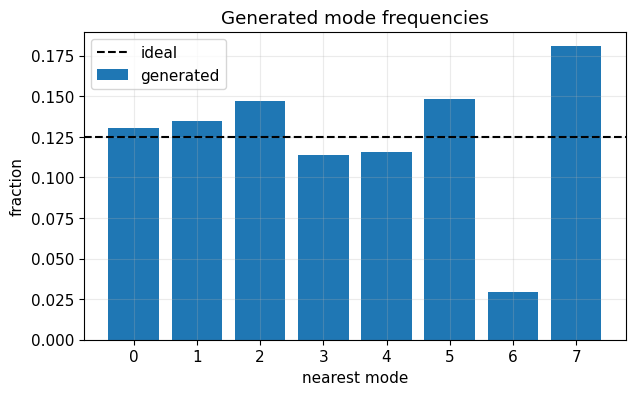

Mean absolute radial error: 0.227
Fraction >3σ from every mode: 8.7%
Modes receiving at least 1% of samples: 8/8
Total variation from uniform mode frequencies: 0.116


In [11]:
angles = 2 * torch.pi * torch.arange(N_MODES) / N_MODES
centers = RADIUS * torch.stack([torch.cos(angles), torch.sin(angles)], 1)
nearest_distance, nearest_mode = torch.cdist(generated, centers).min(1)
frequencies = torch.bincount(nearest_mode, minlength=N_MODES) / len(generated)
radial_error = (generated.norm(dim=1) - RADIUS).abs().mean()
gap_rate = (nearest_distance > 3 * DATA_STD).float().mean()
uniform = torch.full_like(frequencies, 1 / N_MODES)
mode_total_variation = 0.5 * (frequencies - uniform).abs().sum()

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(range(N_MODES), frequencies.numpy(), label="generated")
ax.axhline(1 / N_MODES, color=PLOT_GUIDE_COLOR, linestyle="--", label="ideal")
ax.set(
    xlabel="nearest mode",
    ylabel="fraction",
    title="Generated mode frequencies",
    xticks=range(N_MODES),
)
ax.legend()
plt.show()
print(f"Mean absolute radial error: {radial_error:.3f}")
print(f"Fraction >3σ from every mode: {gap_rate:.1%}")
print(
    f"Modes receiving at least 1% of samples: {(frequencies > .01).sum().item()}/{N_MODES}"
)
print(f"Total variation from uniform mode frequencies: {mode_total_variation:.3f}")

> **Expected observation / interpretation.** Sharp local samples and global diversity are distinct. Uneven or missing nearest-mode counts expose collapse that a favorable adversarial loss (or a small scatter plot) can hide, while off-mode fraction separately tests fidelity to the ring components.

## 12. Why GAN losses are hard to interpret

Unlike maximum likelihood, the two losses depend on a moving opponent:

- a low discriminator loss may mean the discriminator is strong, not that the generator is improving;
- a generator loss near $\log 2$ is consistent with equilibrium, but also does not prove distributional equality;
- comparing raw losses across different GAN formulations is generally meaningless.

Therefore, always pair losses with generated samples and appropriate quality/diversity metrics. On images, common sample-based metrics include FID and precision/recall, each with limitations.

## 13. From 2D points to MNIST

The adversarial objective stays the same. We will replace the multilayer perceptrons with image-appropriate networks in the later notebook:

- a convolutional or transposed-convolutional generator maps $z$ to an image;
- a convolutional discriminator maps an image to one logit;
- output scaling must match preprocessing (for example, `tanh` with images scaled to $[-1,1]$).

Notebook 09 continues this ring-to-MNIST sequence with a spectral-normalized ResNet GAN. The 2D example here makes it easier to visualize decision surfaces, mode collapse, and generator geometry.

## 14. Takeaways and homework experiments

### Takeaways
- GANs learn through a two-player classification game rather than explicit density estimation.
- The non-saturating generator objective supplies stronger gradients than the original minimax update.
- The discriminator is a learned training signal, not a normalized density.
- Sampling is fast, direct, and parallel, but likelihood evaluation is unavailable.
- Adversarial losses alone do not measure sample quality.
- Mode collapse is a central failure mode. Fidelity and diversity must both be checked.

### Mini-experiment 1 — Remove instance noise
- **Hypothesis:** Without early input smoothing, the discriminator separates real and fake supports too easily, producing less informative generator gradients and less stable early coverage.
- **Metric/plot:** Compare checkpoint sample panels, discriminator/generator loss curves, mode counts, and off-mode fraction with and without instance noise.
- **Controls:** Keep initialization seed, data batches, architectures, label smoothing, update ratio, optimizer, epochs, and fixed latent probes unchanged.
- **Interpretation:** Faster discriminator confidence paired with stalled or volatile coverage supports the smoothing explanation. Similar results suggest this toy setup does not need the regularizer. 

### Mini-experiment 2 — Use several discriminator updates per generator update
- **Hypothesis:** A moderate increase may sharpen the training signal, but too many discriminator steps will create imbalance and poorer generator gradients or mode coverage.
- **Metric/plot:** Compare loss trajectories, checkpoint evolution, final mode frequencies, radial error, and off-mode fraction for the baseline and one higher update ratio.
- **Controls:** Keep networks, seed, data, instance-noise schedule, label smoothing, learning rates, and generator-update count fixed.
- **Interpretation:** Better coverage indicates an under-trained baseline discriminator. A discriminator loss near zero with worse coverage indicates overpowering.

### Extensions
- Increase discriminator width relative to the generator.
- Change `LATENT_DIM` to 1 and inspect the geometric bottleneck.
- Remove one-sided label smoothing.
- Deliberately use the saturating minmax generator loss and compare gradients.
- Replace the objective with a Wasserstein GAN with gradient penalty.

## Exit ticket

1. State the roles and objectives of the generator and discriminator, including why the non-saturating generator loss is used.
2. Why is the discriminator neither a normalized density nor required for generation?
3. Which evidence would distinguish sharp samples with good coverage from mode collapse?

<details>
<summary><strong>Self-check answers</strong></summary>

1. The discriminator classifies real versus generated samples. The generator changes generated samples to be classified as real. The non-saturating loss gives stronger gradients when generated samples are initially easy to reject.
2. It estimates a training-time real/fake decision function (or density-ratio-related signal), not an integral-normalized $p(x)$. Once trained, sampling only requires $z\sim p(z)$ and $G_\theta(z)$.
3. Inspect nearest-mode frequencies/number of covered modes together with radial error and off-mode fraction. Sharp points in only a few modes are still collapsed.

</details>

## References and further reading

- [Goodfellow et al., *Generative Adversarial Nets* (NeurIPS 2014)](https://proceedings.neurips.cc/paper/2014/hash/f033ed80deb0234979a61f95710dbe25-Abstract.html): Introduces the adversarial minmax game and non-saturating training heuristic used here.
- [Goodfellow, *NIPS 2016 Tutorial: Generative Adversarial Networks* (arXiv:1701.00160)](https://arxiv.org/abs/1701.00160): Offers accessible theory and practical context for discriminator signals, instability, and mode collapse.